# pvlib frente a datos históricos y mediciones

Comparación del escenario de cielo despejado de **Ineichen**, calculado con pvlib, con dos tipos de referencia:

| Caso | Lugar y periodo inicial | Referencia |
|---|---|---|
| Recurso histórico | Puebla, 2015–2025; detalle horario de 2025 | NASA POWER: estimación derivada de satélites |
| Contraste con instrumentos | Bondville, Illinois, 15–21 de junio de 2025 | NOAA/SURFRAD: mediciones terrestres, junto con NASA POWER para la misma estación |

Se compara **GHI sobre horizontal** en todos los casos. El análisis de Bondville utiliza la ubicación de su estación; sus mediciones no se trasladan a Puebla.

Ineichen representa cielo despejado con turbidez climatológica. Sus diferencias frente a días nublados expresan, en buena parte, una diferencia de condiciones meteorológicas. La comparación con NASA para la misma estación permite evaluar una estimación que sí incorpora información histórica de nubosidad.

Los archivos de entrada se incluyen en `datos_pvlib_vs_datos`. Abra el cuaderno desde la carpeta que contiene ambos, seleccione el kernel del ambiente del curso y ejecute las celdas en orden. Las celdas utilizan esos archivos y solo descargan cuando falta una fuente o se solicita actualizarla.

## 1. Herramientas y parámetros

Cambie los parámetros de esta celda para estudiar otro periodo. Las fuentes originales y sus huellas SHA-256 quedan registradas en `fuentes.json`. Se trabaja en UTC para alinear las series; la hora local se obtiene mediante conversión de zona horaria, sin cambiar el instante físico.

In [1]:
%matplotlib inline
import calendar
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
from urllib.parse import urlsplit, parse_qsl

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pvlib
from pvlib.location import Location
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display

LATITUD = 19.04
LONGITUD = -98.20
ALTITUD_M = 2160
ANIO_INICIAL = 2015
ANIO_FINAL = 2025
ANIO_HORARIO = 2025
PASO_MODELO_MIN = 5
INICIO_NOAA = "2025-06-15"
FIN_NOAA = "2025-06-21"
ACTUALIZAR_DESCARGAS = False

CARPETA_DATOS = Path("datos_pvlib_vs_datos")
CARPETA_DATOS.mkdir(exist_ok=True)
MANIFIESTO = CARPETA_DATOS / "fuentes.json"
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)
print("pvlib:", pvlib.__version__)
print("Carpeta de datos:", CARPETA_DATOS)
assert ANIO_INICIAL <= ANIO_HORARIO <= ANIO_FINAL
assert PASO_MODELO_MIN in (1, 2, 5, 10, 15, 30)

pvlib: 0.16.1
Carpeta de datos: datos_pvlib_vs_datos


## 2. Descarga y trazabilidad de las fuentes

NASA POWER permite consultar series sin clave de acceso. Se solicitan explícitamente UTC y las variables:

- `ALLSKY_SFC_SW_DWN`: radiación global horizontal bajo las condiciones atmosféricas estimadas.
- `CLRSKY_SFC_SW_DWN`: referencia de cielo despejado de NASA.

Los datos POWER son productos satelitales y de modelado; no son una lectura de un sensor instalado en Puebla. Los datos NOAA se descargan de los archivos diarios de una estación terrestre.

La función verifica los archivos conservados antes de utilizarlos. Si cambia ubicación o periodo, identifica la consulta correspondiente y descarga los datos nuevos sin reutilizar una serie de otra ubicación.

In [2]:
sesion = requests.Session()
sesion.mount("https://", HTTPAdapter(max_retries=Retry(
    total=2, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"])))

def clave_url(url):
    partes = urlsplit(url)
    parametros = {}
    for k, v in parse_qsl(partes.query):
        if k in ("latitude", "longitude"):
            v = str(float(v))
        elif k == "parameters":
            v = ",".join(sorted(v.split(",")))
        parametros[k] = v
    return partes.netloc.lower(), partes.path, tuple(sorted(parametros.items()))

def archivo_fuente(url, nombre_nuevo, fuente):
    registros = json.loads(MANIFIESTO.read_text(encoding="utf-8")) if MANIFIESTO.exists() else []
    previo = next((r for r in registros if clave_url(r["url"]) == clave_url(url)), None)
    relativo = previo["archivo"] if previo else nombre_nuevo
    ruta = CARPETA_DATOS / relativo
    if not ruta.resolve().is_relative_to(CARPETA_DATOS.resolve()):
        raise ValueError("La ruta de datos debe permanecer dentro de la carpeta del ejercicio.")
    if ruta.exists() and previo and not ACTUALIZAR_DESCARGAS:
        if hashlib.sha256(ruta.read_bytes()).hexdigest() != previo["sha256"]:
            raise ValueError(f"El archivo cambió: {ruta}. Restaure el original o solicite actualizarlo.")
        return ruta
    respuesta = sesion.get(url, timeout=(15, 90))
    respuesta.raise_for_status()
    if fuente == "NASA POWER":
        contenido = respuesta.json()
        if "ALLSKY_SFC_SW_DWN" not in contenido.get("properties", {}).get("parameter", {}):
            raise ValueError("La respuesta de NASA no contiene la variable solicitada.")
    ruta.parent.mkdir(parents=True, exist_ok=True)
    ruta.write_bytes(respuesta.content)
    registro = {
        "archivo": relativo, "fuente": fuente, "url": respuesta.url,
        "descargado_utc": datetime.now(timezone.utc).isoformat(),
        "bytes": len(respuesta.content),
        "sha256": hashlib.sha256(respuesta.content).hexdigest(),
        "ultima_modificacion": respuesta.headers.get("Last-Modified"),
    }
    registros = [r for r in registros if r["archivo"] != relativo] + [registro]
    MANIFIESTO.write_text(json.dumps(registros, ensure_ascii=False, indent=2), encoding="utf-8")
    return ruta

def consultar_power(temporal, latitud, longitud, inicio, fin):
    parametros = {
        "parameters": "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN", "community": "RE",
        "longitude": longitud, "latitude": latitud, "format": "JSON",
        "time-standard": "UTC", "start": inicio, "end": fin,
    }
    url = requests.Request("GET", f"https://power.larc.nasa.gov/api/temporal/{temporal}/point",
                           params=parametros).prepare().url
    nombre = f"nasa/{temporal}_{latitud:.4f}_{longitud:.4f}_{inicio}_{fin}_UTC.json"
    ruta = archivo_fuente(url, nombre, "NASA POWER")
    documento = json.loads(ruta.read_text(encoding="utf-8"))
    if documento["header"]["time_standard"] != "UTC":
        raise ValueError("La serie debe estar expresada en UTC.")
    coordenadas = documento["geometry"]["coordinates"]
    assert np.isclose(coordenadas[0], longitud) and np.isclose(coordenadas[1], latitud)
    formato = "%Y%m%d" if temporal == "daily" else "%Y%m%d%H"
    datos = pd.DataFrame(documento["properties"]["parameter"])
    datos.index = pd.to_datetime(datos.index, format=formato, utc=True)
    datos = datos.sort_index().apply(pd.to_numeric, errors="coerce")
    datos = datos.mask(datos == documento["header"]["fill_value"])
    datos.columns = ["allsky" if k == "ALLSKY_SFC_SW_DWN" else "clearsky" for k in datos.columns]
    assert datos.index.is_unique
    return datos, documento, ruta

nasa_diario, metadatos_diarios, ruta_diaria = consultar_power(
    "daily", LATITUD, LONGITUD, f"{ANIO_INICIAL}0101", f"{ANIO_FINAL}1231")
nasa_horario, metadatos_horarios, ruta_horaria = consultar_power(
    "hourly", LATITUD, LONGITUD, f"{ANIO_HORARIO}0101", f"{ANIO_HORARIO+1}0101")
display(pd.DataFrame([
    {"Serie": "Diaria", "Unidad": metadatos_diarios["parameters"]["ALLSKY_SFC_SW_DWN"]["units"],
     "Referencia temporal": metadatos_diarios["header"]["time_standard"], "Registros": len(nasa_diario)},
    {"Serie": "Horaria", "Unidad": metadatos_horarios["parameters"]["ALLSKY_SFC_SW_DWN"]["units"],
     "Referencia temporal": metadatos_horarios["header"]["time_standard"], "Registros": len(nasa_horario)},
]))
print("Fuentes de NASA:", metadatos_diarios["header"]["sources"])
print("Coordenadas y elevación del producto:", metadatos_diarios["geometry"]["coordinates"])

,Serie,Unidad,Referencia temporal,Registros
0,Diaria,kW-hr/m^2/day,UTC,4018
1,Horaria,Wh/m^2,UTC,8784


Fuentes de NASA: ['SYN1DEG']
Coordenadas y elevación del producto: [-98.2, 19.04, 2146.67]


## 3. Unidades e interpretación temporal

La respuesta diaria está en **kWh/m² por día**. Se suma para obtener irradiación mensual o anual; no debe multiplicarse otra vez por 24.

La respuesta horaria está en **Wh/m² durante una hora**. Dividir entre 1 h da la irradiancia media en W/m², con el mismo valor numérico. NASA etiqueta el **inicio** de la hora. Se conserva esta etiqueta para agrupar; el modelo se integra durante todo el intervalo.

El cálculo subhorario se aproxima mediante
$$\overline G_h\approx\frac{1}{n}\sum_{j=1}^{n}G(t_{j,medio}),\qquad
H_d\approx\sum_j G_j\Delta t/1000.$$

Se utiliza la altitud de referencia del ejercicio. La elevación del producto satelital corresponde a su celda espacial y puede diferir. La turbidez de Linke del modelo se toma de la climatología incluida en pvlib; no se ajusta a la serie que se compara.

In [3]:
unidad_diaria = metadatos_diarios["parameters"]["ALLSKY_SFC_SW_DWN"]["units"]
unidad_horaria = metadatos_horarios["parameters"]["ALLSKY_SFC_SW_DWN"]["units"]
assert unidad_diaria == "kW-hr/m^2/day", unidad_diaria
assert unidad_horaria == "Wh/m^2", unidad_horaria
print("Valores faltantes diarios:")
display(nasa_diario.isna().sum().to_frame("Cantidad"))
print("Valores faltantes horarios:")
display(nasa_horario.isna().sum().to_frame("Cantidad"))

def ineichen_intervalos(sitio, inicio, fin, paso_min):
    inicios = pd.date_range(inicio, fin, freq=f"{paso_min}min", inclusive="left", tz="UTC")
    centros = inicios + pd.Timedelta(minutes=paso_min/2)
    posicion = sitio.get_solarposition(centros)
    cielo = sitio.get_clearsky(centros, model="ineichen", solar_position=posicion)
    serie = pd.Series(cielo["ghi"].to_numpy(), index=inicios, name="ineichen")
    por_hora = serie.resample("h").mean()
    por_dia = serie.resample("D").sum() * paso_min/60/1000
    return por_hora, por_dia

sitio_puebla = Location(LATITUD, LONGITUD, "UTC", ALTITUD_M, name="Puebla")
bloques_diarios = []
modelo_horario = None
for anio in range(ANIO_INICIAL, ANIO_FINAL+1):
    hora, dia = ineichen_intervalos(sitio_puebla, f"{anio}-01-01", f"{anio+1}-01-01", PASO_MODELO_MIN)
    bloques_diarios.append(dia)
    if anio == ANIO_HORARIO:
        modelo_horario = hora
modelo_diario = pd.concat(bloques_diarios)
diario = nasa_diario.rename(columns={"allsky": "nasa_allsky", "clearsky": "nasa_clearsky"}).join(modelo_diario)
calendario = pd.date_range(f"{ANIO_INICIAL}-01-01", f"{ANIO_FINAL+1}-01-01",
                           freq="D", inclusive="left", tz="UTC")
diario = diario.reindex(calendario)
display(diario.head())

Valores faltantes diarios:


,Cantidad
allsky,0
clearsky,0


Valores faltantes horarios:


,Cantidad
allsky,0
clearsky,0


,nasa_allsky,nasa_clearsky,ineichen
2015-01-01 00:00:00+00:00,4.944,5.295,5.836
2015-01-02 00:00:00+00:00,4.756,5.185,5.843
2015-01-03 00:00:00+00:00,4.144,5.279,5.851
2015-01-04 00:00:00+00:00,3.731,5.079,5.860
2015-01-05 00:00:00+00:00,2.442,5.251,5.870


## 4. Variabilidad entre años

Los totales anuales se comparan únicamente cuando el año tiene todos los días válidos en las tres series. Los huecos no se sustituyen por cero.

Se identifica el año de menor recurso **dentro de la muestra**, su diferencia respecto al promedio de los años completos y el coeficiente de variación. Estos resultados describen el periodo descargado; no establecen el peor año futuro ni prueban por sí solos una anomalía climática.

,NASA all-sky [kWh/m²],NASA claro [kWh/m²],Ineichen [kWh/m²],dias_validos,dias_esperados,completo,desviacion_media_pct
2015,1936.150,2478.396,2837.302,365,365,True,-5.001
2016,1963.025,2512.350,2843.025,366,366,True,-3.682
2017,2050.091,2521.685,2837.308,365,365,True,0.590
2018,2029.956,2504.767,2837.307,365,365,True,-0.398
2019,2091.153,2511.421,2837.320,365,365,True,2.605
2020,2102.469,2527.440,2843.001,366,366,True,3.160
2021,2045.698,2509.233,2837.292,365,365,True,0.374
2022,2055.749,2505.263,2837.259,365,365,True,0.867
2023,2077.787,2514.265,2837.245,365,365,True,1.949
2024,2056.302,2502.873,2842.958,366,366,True,0.895


Promedio histórico NASA all-sky: 2038.1 kWh/m²/año
Año de menor recurso: 2015; diferencia respecto al promedio: -5.00 %
Año de mayor recurso: 2020
Coeficiente de variación interanual: 2.51 %


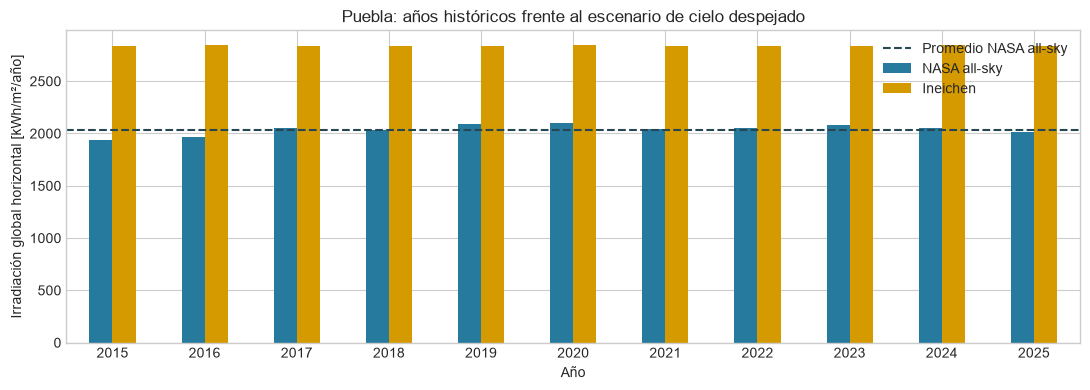

In [4]:
columnas_diarias = ["nasa_allsky", "nasa_clearsky", "ineichen"]
validos_diarios = diario[columnas_diarias].notna().all(axis=1)
comparables = diario[columnas_diarias].where(validos_diarios)
anual = comparables.groupby(comparables.index.year).sum(min_count=1)
anual["dias_validos"] = validos_diarios.groupby(diario.index.year).sum()
anual["dias_esperados"] = [366 if calendar.isleap(int(a)) else 365 for a in anual.index]
anual["completo"] = anual["dias_validos"] == anual["dias_esperados"]
anual.loc[~anual["completo"], columnas_diarias] = np.nan
promedio_anual = anual.loc[anual["completo"], "nasa_allsky"].mean()
anual["desviacion_media_pct"] = 100*(anual["nasa_allsky"]/promedio_anual-1)
display(anual.rename(columns={
    "nasa_allsky": "NASA all-sky [kWh/m²]", "nasa_clearsky": "NASA claro [kWh/m²]",
    "ineichen": "Ineichen [kWh/m²]"}))
completos = anual.loc[anual["completo"]]
assert len(completos) >= 2, "Se necesitan al menos dos años completos para evaluar variabilidad."
anio_bajo = int(completos["nasa_allsky"].idxmin())
anio_alto = int(completos["nasa_allsky"].idxmax())
cv = 100*completos["nasa_allsky"].std(ddof=1)/promedio_anual
print(f"Promedio histórico NASA all-sky: {promedio_anual:.1f} kWh/m²/año")
print(f"Año de menor recurso: {anio_bajo}; diferencia respecto al promedio: {anual.loc[anio_bajo, 'desviacion_media_pct']:.2f} %")
print(f"Año de mayor recurso: {anio_alto}")
print(f"Coeficiente de variación interanual: {cv:.2f} %")

fig, ax = plt.subplots(figsize=(11, 4))
completos[["nasa_allsky", "ineichen"]].plot.bar(ax=ax, color=["#267A9E", "#D49A00"], rot=0)
ax.axhline(promedio_anual, color="#264653", linestyle="--", label="Promedio NASA all-sky")
ax.set(xlabel="Año", ylabel="Irradiación global horizontal [kWh/m²/año]",
       title="Puebla: años históricos frente al escenario de cielo despejado")
ax.legend(["Promedio NASA all-sky", "NASA all-sky", "Ineichen"])
fig.tight_layout()
plt.show()

## 5. Estacionalidad y nubosidad

Se calcula la irradiación diaria media de cada mes usando las mismas fechas disponibles. Se comparan NASA all-sky, NASA clear-sky e Ineichen.

Una separación estacional entre all-sky y los escenarios despejados muestra por qué no basta con usar geometría solar para representar el clima. Las diferencias entre los dos escenarios de cielo despejado también dependen de sus hipótesis atmosféricas y fuentes.

,nasa_allsky,nasa_clearsky,ineichen,dias_validos
1,4.907,5.574,6.083,341
2,5.816,6.399,6.967,311
3,6.437,7.244,7.982,341
4,6.606,7.678,8.660,330
5,6.328,7.739,8.897,341
6,5.663,7.818,8.971,330
7,5.800,7.775,9.042,341
8,5.684,7.621,8.813,341
9,5.059,7.076,8.256,330
10,5.030,6.451,7.350,341


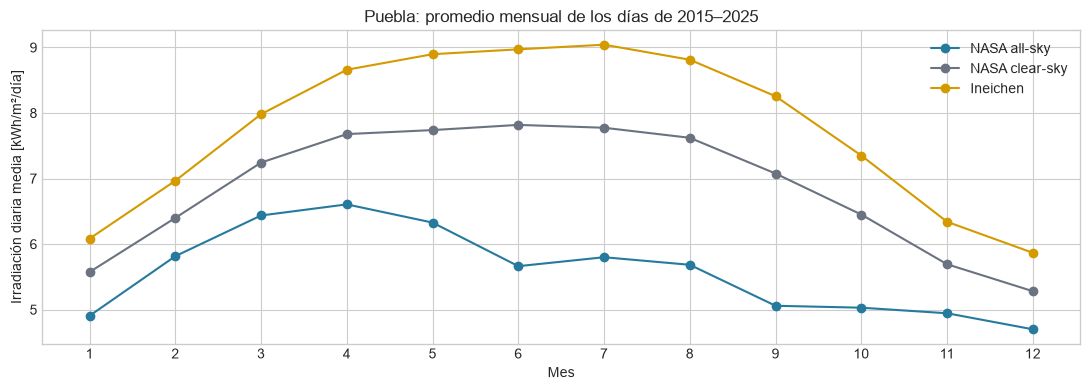

In [5]:
climatologia = comparables.groupby(comparables.index.month).mean()
climatologia["dias_validos"] = validos_diarios.groupby(diario.index.month).sum()
display(climatologia)
fig, ax = plt.subplots(figsize=(11, 4))
for columna, etiqueta, color in [
    ("nasa_allsky", "NASA all-sky", "#267A9E"),
    ("nasa_clearsky", "NASA clear-sky", "#6B7280"),
    ("ineichen", "Ineichen", "#D49A00")]:
    ax.plot(climatologia.index, climatologia[columna], marker="o", label=etiqueta, color=color)
ax.set(xticks=range(1, 13), xlabel="Mes", ylabel="Irradiación diaria media [kWh/m²/día]",
       title=f"Puebla: promedio mensual de los días de {ANIO_INICIAL}–{ANIO_FINAL}")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Comparación horaria del año seleccionado

Se usan únicamente horas coincidentes. Las estadísticas diurnas consideran horas con irradiancia media de cielo despejado superior a 20 W/m² para no diluir las diferencias con horas nocturnas.

$$MBE=\frac{1}{N}\sum(M_i-R_i),\qquad
RMSE=\sqrt{\frac{1}{N}\sum(M_i-R_i)^2}.$$
$$nMBE=100\,MBE/\overline R,\qquad nRMSE=100\,RMSE/\overline R.$$

M representa el modelo comparado y R la referencia indicada. Un sesgo positivo significa que M supera a R. Frente a NASA all-sky, estas métricas describen discrepancias entre escenarios y fuentes; no son una validación contra instrumentos.

,Comparación,N,MBE [W/m²],RMSE [W/m²],nMBE [%],nRMSE [%]
0,Ineichen frente a NASA all-sky,4369,189.157,252.261,41.130,54.851
1,Ineichen frente a NASA clear-sky,4369,79.206,91.606,13.899,16.076


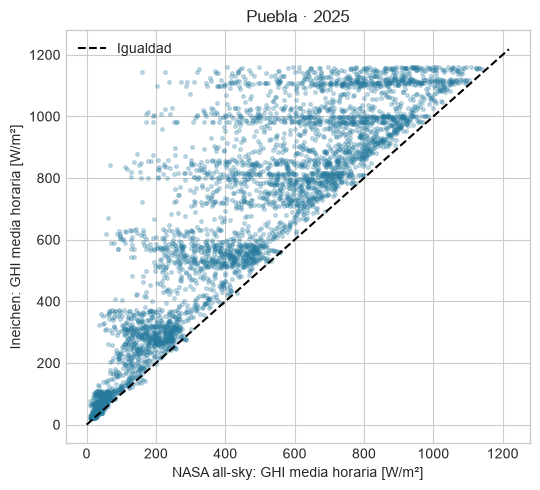

In [6]:
def metricas(referencia, modelo, nombre):
    pares = pd.DataFrame({"referencia": referencia, "modelo": modelo}).replace([np.inf, -np.inf], np.nan).dropna()
    if pares.empty or pares["referencia"].mean() <= 0:
        raise ValueError("No hay pares válidos con referencia media positiva.")
    diferencia = pares["modelo"]-pares["referencia"]
    mbe = diferencia.mean()
    rmse = np.sqrt(np.mean(diferencia**2))
    return {"Comparación": nombre, "N": len(pares), "MBE [W/m²]": mbe, "RMSE [W/m²]": rmse,
            "nMBE [%]": 100*mbe/pares["referencia"].mean(),
            "nRMSE [%]": 100*rmse/pares["referencia"].mean()}

horario = nasa_horario.rename(columns={"allsky": "nasa_allsky", "clearsky": "nasa_clearsky"}).join(modelo_horario)
horario = horario.loc[(horario.index >= f"{ANIO_HORARIO}-01-01") &
                      (horario.index < f"{ANIO_HORARIO+1}-01-01")].copy()
assert len(horario) == (366 if calendar.isleap(ANIO_HORARIO) else 365)*24
mascara_diurna = horario["ineichen"] > 20
estadisticas_puebla = pd.DataFrame([
    metricas(horario.loc[mascara_diurna, "nasa_allsky"], horario.loc[mascara_diurna, "ineichen"],
             "Ineichen frente a NASA all-sky"),
    metricas(horario.loc[mascara_diurna, "nasa_clearsky"], horario.loc[mascara_diurna, "ineichen"],
             "Ineichen frente a NASA clear-sky"),
])
display(estadisticas_puebla)
fig, ax = plt.subplots(figsize=(5.5, 5))
pares = horario.loc[mascara_diurna, ["nasa_allsky", "ineichen"]].dropna()
ax.scatter(pares["nasa_allsky"], pares["ineichen"], s=7, alpha=.25, color="#267A9E")
limite = float(pares.max().max())*1.05
ax.plot([0, limite], [0, limite], "--", color="black", label="Igualdad")
ax.set(xlabel="NASA all-sky: GHI media horaria [W/m²]",
       ylabel="Ineichen: GHI media horaria [W/m²]", title=f"Puebla · {ANIO_HORARIO}")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Dos días con distinto aporte relativo

Se seleccionan días completos de 24 horas y se calcula la razón entre la energía all-sky y clear-sky de NASA. Los días de menor y mayor razón permiten observar dos condiciones distintas sin elegirlas por conveniencia visual.

La clasificación es relativa a esta serie; una razón alta no certifica ausencia de nubes.

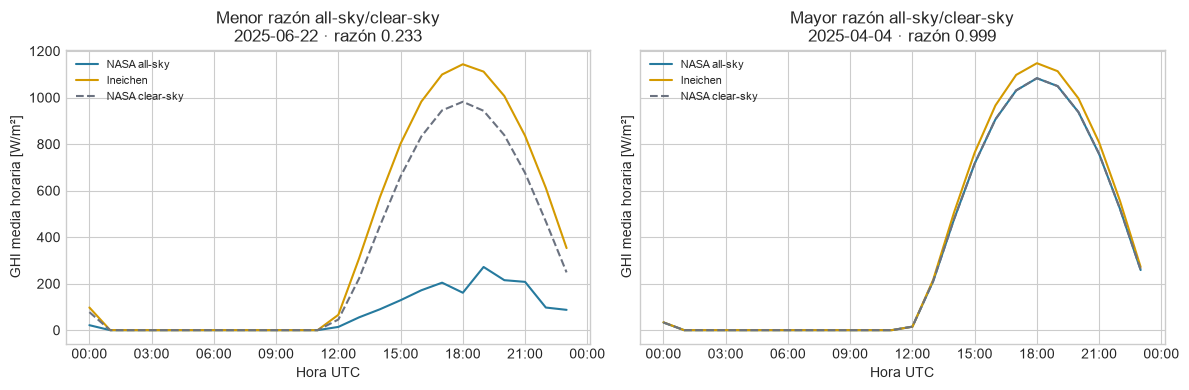

Diferencia absoluta media entre NASA horario integrado y producto diario: 0.00006 kWh/m²


In [7]:
cuenta_horas = horario[["nasa_allsky","nasa_clearsky"]].notna().all(axis=1).resample("D").sum()
energia_horaria = horario[["nasa_allsky","nasa_clearsky","ineichen"]].resample("D").sum(min_count=24)/1000
candidatos = energia_horaria.loc[(cuenta_horas == 24) & (energia_horaria["nasa_clearsky"] > 0)].copy()
candidatos["razon"] = candidatos["nasa_allsky"]/candidatos["nasa_clearsky"]
dias_puebla = [candidatos["razon"].idxmin(), candidatos["razon"].idxmax()]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, fecha, etiqueta in zip(ejes, dias_puebla, ["Menor razón all-sky/clear-sky", "Mayor razón all-sky/clear-sky"]):
    dia = horario.loc[fecha.strftime("%Y-%m-%d")]
    ax.plot(dia.index, dia["nasa_allsky"], color="#267A9E", label="NASA all-sky")
    ax.plot(dia.index, dia["ineichen"], color="#D49A00", label="Ineichen")
    ax.plot(dia.index, dia["nasa_clearsky"], color="#6B7280", linestyle="--", label="NASA clear-sky")
    ax.set(title=f"{etiqueta}\n{fecha:%Y-%m-%d} · razón {candidatos.loc[fecha, 'razon']:.3f}",
           xlabel="Hora UTC", ylabel="GHI media horaria [W/m²]")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=timezone.utc))
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# La consistencia entre productos se revisa sin imponer igualdad exacta.
control_diario = energia_horaria[["nasa_allsky"]].join(
    nasa_diario[["allsky"]].rename(columns={"allsky": "nasa_producto_diario"}))
control_diario["diferencia_kwh_m2"] = control_diario["nasa_allsky"]-control_diario["nasa_producto_diario"]
print("Diferencia absoluta media entre NASA horario integrado y producto diario:",
      f"{control_diario['diferencia_kwh_m2'].abs().mean():.5f} kWh/m²")

## 8. Mediciones terrestres: NOAA/SURFRAD

Se utiliza Bondville, Illinois, durante una semana. Se lee la ubicación incluida en los propios archivos de estación y se calcula un modelo para esa ubicación.

Los registros NOAA son promedios de un minuto etiquetados al **final** del intervalo. Se resta un minuto para etiquetar su inicio y se evalúa la geometría a los 30 segundos. Se descarga además el archivo del día siguiente para incluir el minuto que termina exactamente al cerrar el periodo.

La documentación NOAA define flag=0 como dato que pasó sus controles. Se conservan valores finitos de GHI con flag=0 y GHI no negativa. No se eliminan observaciones por superar al modelo. Los huecos y los registros rechazados se conservan como ausencias. El conteo de negativos incluye registros nocturnos y no representa por sí solo la disponibilidad diurna de la estación.

In [8]:
inicio_noaa = pd.Timestamp(INICIO_NOAA, tz="UTC")
fin_noaa = pd.Timestamp(FIN_NOAA, tz="UTC")+pd.Timedelta(days=1)
archivos_noaa = []
for fecha in pd.date_range(inicio_noaa, fin_noaa, freq="D"):
    nombre = f"bon{fecha:%y}{fecha.dayofyear:03d}.dat"
    url = f"https://gml.noaa.gov/aftp/data/radiation/surfrad/Bondville_IL/{fecha.year}/{nombre}"
    archivos_noaa.append(archivo_fuente(url, "surfrad/"+nombre, "NOAA SURFRAD"))
archivo_formato = archivo_fuente(
    "https://gml.noaa.gov/aftp/data/radiation/surfrad/Bondville_IL/README_SURFRAD.txt",
    "surfrad/formato_NOAA_SURFRAD.txt", "NOAA SURFRAD")

bloques_noaa = []
metadatos_estacion = None
for ruta in archivos_noaa:
    bloque, meta = pvlib.iotools.read_surfrad(ruta)
    if metadatos_estacion is None:
        metadatos_estacion = meta
    for campo in ("name", "latitude", "longitude", "elevation"):
        assert meta[campo] == metadatos_estacion[campo], f"Metadatos diferentes en {ruta}"
    bloques_noaa.append(bloque)
noaa_original = pd.concat(bloques_noaa).sort_index()
assert noaa_original.index.is_unique
noaa_original.index = noaa_original.index-pd.Timedelta(minutes=1)
noaa_original = noaa_original.loc[(noaa_original.index >= inicio_noaa) & (noaa_original.index < fin_noaa)]
minutos_esperados = pd.date_range(inicio_noaa, fin_noaa, freq="min", inclusive="left")
noaa = noaa_original.reindex(minutos_esperados).copy()
validos_noaa = noaa["ghi"].notna() & noaa["ghi_flag"].eq(0) & noaa["ghi"].ge(0)
noaa["ghi_valida"] = noaa["ghi"].where(validos_noaa)
display(pd.Series(metadatos_estacion).to_frame("Metadatos del archivo"))
display(pd.DataFrame({
    "Minutos esperados": [len(noaa)], "Minutos presentes": [len(noaa_original)],
    "GHI con flag 0": [int(noaa["ghi_flag"].eq(0).sum())],
    "GHI válida no negativa": [int(validos_noaa.sum())],
    "Registros rechazados o ausentes": [int((~validos_noaa).sum())],
}))
print("Documento original de formato y controles:", archivo_formato)

,Metadatos del archivo
name,Bondville
latitude,40.05
longitude,-88.37
elevation,213.0
surfrad_version,1
tz,UTC


,Minutos esperados,Minutos presentes,GHI con flag 0,GHI válida no negativa,Registros rechazados o ausentes
0,10080,10080,10004,6311,3769


Documento original de formato y controles: datos_pvlib_vs_datos\surfrad\formato_NOAA_SURFRAD.txt


## 9. Alinear el modelo y NASA con la estación

El modelo se evalúa en el centro de cada minuto de NOAA. Después, se forman medias horarias con las mismas muestras válidas. Para compararlas con NASA se exigen **60 minutos válidos por hora** y un aporte de cielo despejado superior a 20 W/m².

De este modo, una hora con minutos faltantes no se presenta como una hora completa. Las estadísticas utilizan exactamente las mismas horas para ambos modelos.

In [9]:
sitio_noaa = Location(metadatos_estacion["latitude"], metadatos_estacion["longitude"],
                      "UTC", metadatos_estacion["elevation"], name=metadatos_estacion["name"])
centros_noaa = noaa.index+pd.Timedelta(seconds=30)
posicion_noaa = sitio_noaa.get_solarposition(centros_noaa)
modelo_noaa = sitio_noaa.get_clearsky(centros_noaa, model="ineichen", solar_position=posicion_noaa)
noaa["ineichen"] = modelo_noaa["ghi"].to_numpy()
noaa["ineichen_muestras_validas"] = noaa["ineichen"].where(validos_noaa)

nasa_estacion, metadata_nasa_estacion, ruta_nasa_estacion = consultar_power(
    "hourly", metadatos_estacion["latitude"], metadatos_estacion["longitude"],
    inicio_noaa.strftime("%Y%m%d"), (fin_noaa-pd.Timedelta(days=1)).strftime("%Y%m%d"))
horas_estacion = pd.DataFrame({
    "medida": noaa["ghi_valida"].resample("h").mean(),
    "ineichen": noaa["ineichen_muestras_validas"].resample("h").mean(),
    "minutos_validos": validos_noaa.resample("h").sum(),
}).join(nasa_estacion[["allsky"]].rename(columns={"allsky": "nasa_allsky"}))
aceptadas = (horas_estacion["minutos_validos"] == 60) & (horas_estacion["ineichen"] > 20)
pares_estacion = horas_estacion.loc[aceptadas, ["medida", "ineichen", "nasa_allsky"]].dropna()
assert len(pares_estacion) >= 10, "La semana no reúne suficientes horas diurnas completas."
estadisticas_estacion = pd.DataFrame([
    metricas(pares_estacion["medida"], pares_estacion["ineichen"], "Ineichen frente a SURFRAD"),
    metricas(pares_estacion["medida"], pares_estacion["nasa_allsky"], "NASA all-sky frente a SURFRAD"),
])
display(estadisticas_estacion)
print(f"Horas diurnas completas usadas en ambas comparaciones: {len(pares_estacion)}")
print("GHI y modelo corresponden a Bondville; no se comparan sus mediciones con la simulación de Puebla.")

,Comparación,N,MBE [W/m²],RMSE [W/m²],nMBE [%],nRMSE [%]
0,Ineichen frente a SURFRAD,69,116.807,234.953,29.140,58.613
1,NASA all-sky frente a SURFRAD,69,-12.621,95.772,-3.148,23.892


Horas diurnas completas usadas en ambas comparaciones: 69
GHI y modelo corresponden a Bondville; no se comparan sus mediciones con la simulación de Puebla.


## 10. Curvas medidas y comparación directa

Las horas sin cobertura suficiente permanecen como ausencias en las curvas. La línea de igualdad en la dispersión representa coincidencia con la medición.

Compare el sesgo y la dispersión de NASA all-sky e Ineichen. La diferencia no se interpreta como competencia entre programas: el primero utiliza información atmosférica histórica y el segundo representa cielo despejado.

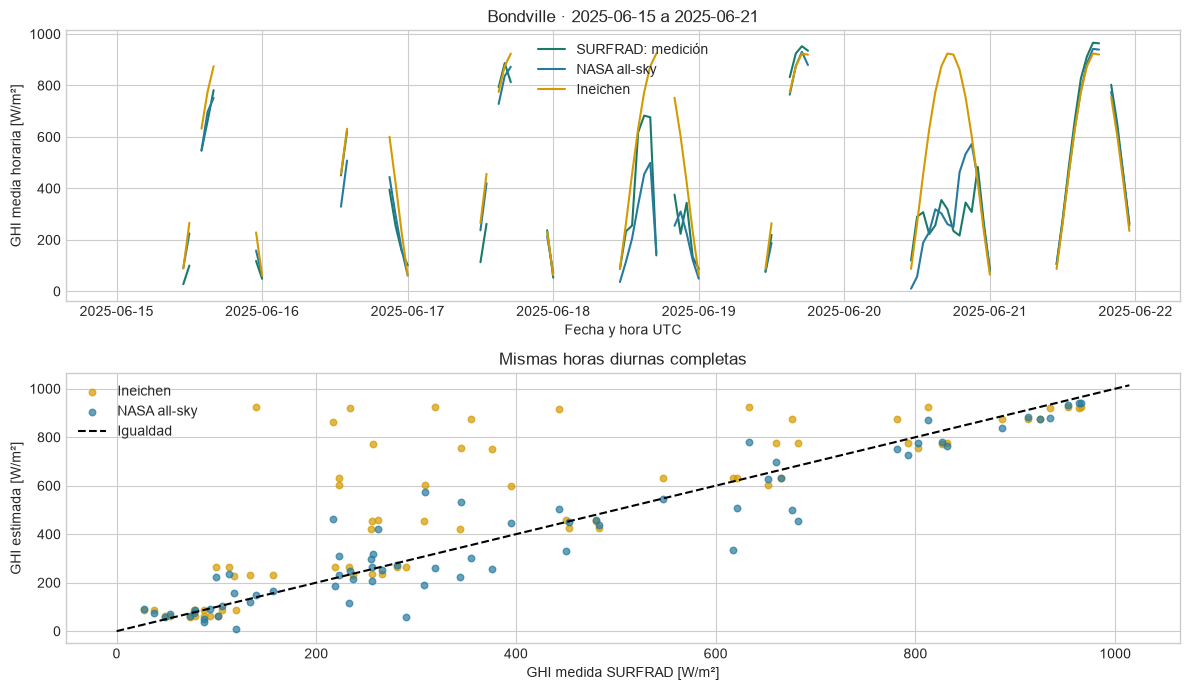

In [10]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 7))
horas_grafica = horas_estacion[["medida","ineichen","nasa_allsky"]].where(
    horas_estacion["minutos_validos"].eq(60), np.nan)
for columna, etiqueta, color in [
    ("medida", "SURFRAD: medición", "#197A69"),
    ("nasa_allsky", "NASA all-sky", "#267A9E"),
    ("ineichen", "Ineichen", "#D49A00")]:
    ejes[0].plot(horas_grafica.index, horas_grafica[columna], label=etiqueta, color=color)
ejes[0].set(title=f"Bondville · {INICIO_NOAA} a {FIN_NOAA}", ylabel="GHI media horaria [W/m²]", xlabel="Fecha y hora UTC")
ejes[0].legend()
for columna, etiqueta, color in [("ineichen","Ineichen","#D49A00"), ("nasa_allsky","NASA all-sky","#267A9E")]:
    ejes[1].scatter(pares_estacion["medida"], pares_estacion[columna], label=etiqueta, color=color, alpha=.7, s=22)
limite = float(pares_estacion.max().max())*1.05
ejes[1].plot([0,limite],[0,limite], "--", color="black", label="Igualdad")
ejes[1].set(xlabel="GHI medida SURFRAD [W/m²]", ylabel="GHI estimada [W/m²]", title="Mismas horas diurnas completas")
ejes[1].legend()
fig.tight_layout()
plt.show()

## 11. Interpretación de los resultados

Las respuestas siguientes se calculan con los datos descargados. El año de menor recurso y las diferencias entre modelos pueden cambiar al seleccionar otro periodo.

El análisis no incorpora transposición a una superficie inclinada, sombras locales ni rendimiento de un panel. Primero se contrasta el recurso horizontal; esas etapas pueden evaluarse después sin confundir sus efectos.

In [11]:
exceso_despejado = 100*(completos["ineichen"].mean()/promedio_anual-1)
baja = anual.loc[anio_bajo, "desviacion_media_pct"]
rmse_ineichen = estadisticas_estacion.iloc[0]["RMSE [W/m²]"]
rmse_nasa = estadisticas_estacion.iloc[1]["RMSE [W/m²]"]
print(f"Puebla: el año de menor recurso en la muestra es {anio_bajo}, {abs(baja):.2f} % por debajo del promedio.")
print(f"El promedio anual de Ineichen difiere {exceso_despejado:+.2f} % del promedio NASA all-sky.")
print(f"Bondville: RMSE horario frente a instrumentos = {rmse_ineichen:.1f} W/m² con Ineichen y {rmse_nasa:.1f} W/m² con NASA all-sky.")
print(f"La referencia terrestre utiliza {len(pares_estacion)} horas completas de una semana; no caracteriza todo el clima anual.")
print("La posición solar y los modelos siguen siendo útiles; la fuente meteorológica elegida condiciona la representatividad del resultado.")

Puebla: el año de menor recurso en la muestra es 2015, 5.00 % por debajo del promedio.
El promedio anual de Ineichen difiere +39.29 % del promedio NASA all-sky.
Bondville: RMSE horario frente a instrumentos = 235.0 W/m² con Ineichen y 95.8 W/m² con NASA all-sky.
La referencia terrestre utiliza 69 horas completas de una semana; no caracteriza todo el clima anual.
La posición solar y los modelos siguen siendo útiles; la fuente meteorológica elegida condiciona la representatividad del resultado.


## Preguntas para analizar en clase

1. ¿Por qué el escenario despejado cambia poco entre años, mientras el recurso histórico sí cambia?
2. ¿En qué meses de Puebla se separan más las curvas all-sky y clear-sky?
3. ¿Qué diferencia existe entre un dato satelital y una observación de una estación?
4. ¿Por qué el modelo debe evaluarse en Bondville al contrastarlo con sus instrumentos?
5. ¿Qué efecto tendría ignorar la zona horaria o interpretar el final del minuto como su inicio?
6. ¿Qué diseño sería más sensible a varios días de recurso bajo: uno conectado a red o uno aislado con baterías?
7. ¿Por qué una semana de comparación y once años históricos no garantizan conocer todos los extremos futuros?

Un TMY representa condiciones típicas; para estudiar variabilidad y años bajos se necesitan series de años individuales. El peor año de una muestra histórica no equivale a un límite físico del recurso futuro.

## Fuentes y reproducción

- [NASA POWER: metodología y procedencia de los datos](https://power.larc.nasa.gov/docs/methodology/).
- [NASA POWER: API horaria, valores medios y UTC](https://power.larc.nasa.gov/docs/services/api/temporal/hourly/).
- [NASA POWER: interpretación de la etiqueta de inicio de hora](https://power.larc.nasa.gov/docs/faqs/other/).
- [NASA POWER: API diaria](https://power.larc.nasa.gov/docs/services/api/temporal/daily/).
- [NOAA/SURFRAD: red de medición](https://gml.noaa.gov/grad/surfrad/).
- [NOAA: archivo público de Bondville](https://gml.noaa.gov/aftp/data/radiation/surfrad/Bondville_IL/).
- [NOAA: formato, promedios y flags de calidad](https://gml.noaa.gov/aftp/data/radiation/surfrad/Bondville_IL/README_SURFRAD.txt).
- [pvlib: lector de SURFRAD](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.iotools.read_surfrad.html).
- [pvlib: estimación de cielo despejado](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.location.Location.get_clearsky.html).

`fuentes.json` conserva la URL exacta, fecha de descarga en UTC, tamaño y huella SHA-256 de cada archivo original. Los controles del cuaderno rechazan cambios inadvertidos en los archivos conservados. Las mediciones no se sustituyen por datos sintéticos cuando falta una descarga.

In [12]:
fuentes_utilizadas = json.loads(MANIFIESTO.read_text(encoding="utf-8"))
display(pd.DataFrame(fuentes_utilizadas)[["archivo", "fuente", "descargado_utc", "sha256"]])
assert np.isclose(completos["nasa_allsky"].mean(), promedio_anual)
assert estadisticas_estacion["N"].nunique() == 1
assert (pares_estacion.index.tz is not None) and (horario.index.tz is not None)
print("Comprobaciones de unidades, cronología, integridad y pares de comparación: correctas.")

,archivo,fuente,descargado_utc,sha256
0,nasa/puebla_diario_2015_2025_utc.json,NASA POWER,2026-11-18T06:11:02.072652+00:00,679082baad958124f09dd4f68630c3f411ab13097a64ce...
1,nasa/puebla_horario_2025_utc.json,NASA POWER,2026-11-18T06:11:02.673705+00:00,3e4731e6fd9691a586d12b7ea517b6bf9bd09924f1c713...
2,surfrad/bon25166.dat,NOAA SURFRAD,2026-11-18T06:11:03.197478+00:00,25b5d241f78361921cf6abce1cd2b0c53c711122c5f5c4...
3,surfrad/bon25167.dat,NOAA SURFRAD,2026-11-18T06:11:03.808702+00:00,e5a5cbf6fcef22543659415280ef1379b319aaec937f47...
4,surfrad/bon25168.dat,NOAA SURFRAD,2026-11-18T06:11:04.326213+00:00,ae149719cf41fd6ceb7191fb39ef1f16762d1ec2561ab0...
5,surfrad/bon25169.dat,NOAA SURFRAD,2026-11-18T06:11:04.482891+00:00,baa0e03de52f69448393e12453812693e8fc219e3c0fa6...
6,surfrad/bon25170.dat,NOAA SURFRAD,2026-11-18T06:11:04.544258+00:00,835961bb8c34c2f47a3473986d53f22a83f39eee088479...
7,surfrad/bon25171.dat,NOAA SURFRAD,2026-11-18T06:11:04.623250+00:00,1be2c0902a945a8b850b51d25c95cafa63cb7dcbeb5f87...
8,surfrad/bon25172.dat,NOAA SURFRAD,2026-11-18T06:11:04.685762+00:00,82c3c3ad4c475518b2ae780646d956a1ebc60257866cb5...
9,surfrad/formato_NOAA_SURFRAD.txt,NOAA SURFRAD,2026-11-18T06:12:36.241975+00:00,ed3e5c16f169a9def997877e6037735977f2761c9c3c39...


Comprobaciones de unidades, cronología, integridad y pares de comparación: correctas.
